## 1. Imports and configuration

In [1]:
# Import libraries
from pathlib import Path
import json
import random
import copy
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


## 2. Load dataset artifacts

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Define project paths and load metadata

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/AAI-521/project"
)

DATASET_DIR = PROJECT_ROOT / "datasets" / "camvid"

OUTPUT_DIR = DATASET_DIR / "preprocessed"

TRAIN_CSV = OUTPUT_DIR / "train_metadata.csv"
VAL_CSV = OUTPUT_DIR / "validation_metadata.csv"
TEST_CSV = OUTPUT_DIR / "test_metadata.csv"

ACTIVE_CLASSES_CSV = OUTPUT_DIR / "active_classes.csv"

AUGMENTATION_CONFIG = OUTPUT_DIR / "augmentation_config.json"

# Load metadata
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

# Load active classes
ACTIVE_CLASSES = pd.read_csv(
    ACTIVE_CLASSES_CSV
)["class_name"].tolist()

NUM_CLASSES = len(ACTIVE_CLASSES)

# Load augmentation configuration
with open(AUGMENTATION_CONFIG, "r") as f:
    augmentation_config = json.load(f)

IMAGE_SIZE = tuple(
    augmentation_config["image_size"]
)

BATCH_SIZE = augmentation_config["batch_size"]

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("Number of classes:", NUM_CLASSES)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

Training samples: 406
Validation samples: 171
Testing samples: 124
Number of classes: 29
Image size: (224, 224)
Batch size: 32


In [4]:
# Validate metadata and class columns
assert NUM_CLASSES == 29, (
    f"Expected 29 active classes, found {NUM_CLASSES}"
)

for split_name, split_df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    assert all(
        class_name in split_df.columns
        for class_name in ACTIVE_CLASSES
    ), f"Missing class columns in {split_name}"

    assert split_df["image_path"].apply(
        lambda path: Path(path).is_file()
    ).all(), f"Missing image files in {split_name}"

    print(
        f"{split_name}: {len(split_df)} samples validated"
    )

print("\nMetadata validation passed.")

train: 406 samples validated
validation: 171 samples validated
test: 124 samples validated

Metadata validation passed.


### 2.1 Data loader initialization

In [5]:
# Define transformation
PADDING_COLOR = (124, 116, 104)
NUM_WORKERS = 2

resize_transform = transforms.Resize((168, 224))

pad_transform = transforms.Pad(
    padding=(0, 28, 0, 28),
    fill=PADDING_COLOR
)

augmentation_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),

    transforms.RandomAffine(
        degrees=3,
        translate=(0.02, 0.02),
        scale=(0.98, 1.02),
        fill=PADDING_COLOR
    ),

    transforms.RandomApply(
        [
            transforms.GaussianBlur(
                kernel_size=3,
                sigma=(0.1, 1.0)
            )
        ],
        p=0.15
    )
])

train_transform = transforms.Compose([
    resize_transform,
    augmentation_transform,
    pad_transform,
    transforms.ToTensor()
])

evaluation_transform = transforms.Compose([
    resize_transform,
    pad_transform,
    transforms.ToTensor()
])

print("Training and evaluation transformations initialized.")

Training and evaluation transformations initialized.


In [6]:
# Define dataset class
class CamVidClassificationDataset(Dataset):

    def __init__(self, metadata, active_classes, transform=None):
        self.metadata = metadata.reset_index(drop=True)
        self.active_classes = active_classes
        self.transform = transform

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, index):

        row = self.metadata.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        labels = torch.tensor(
            row[self.active_classes].values.astype(np.float32),
            dtype=torch.float32
        )

        return {
            "image": image,
            "labels": labels,
            "filename": row["filename"]
        }

In [7]:
# Create dataset and dataset loaders
train_dataset = CamVidClassificationDataset(
    train_df,
    ACTIVE_CLASSES,
    train_transform
)

val_dataset = CamVidClassificationDataset(
    val_df,
    ACTIVE_CLASSES,
    evaluation_transform
)

test_dataset = CamVidClassificationDataset(
    test_df,
    ACTIVE_CLASSES,
    evaluation_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 13
Validation batches: 6
Testing batches: 4


## 3. Analyze class imbalance

In [8]:
# Calculate training set class frequencies
positive_counts = (
    train_df[ACTIVE_CLASSES]
    .sum()
    .astype(int)
)

negative_counts = len(train_df) - positive_counts

class_distribution = pd.DataFrame({
    "class_name": ACTIVE_CLASSES,
    "positive_samples": positive_counts.values,
    "negative_samples": negative_counts.values,
})

class_distribution["positive_percentage"] = (
    class_distribution["positive_samples"]
    / len(train_df) * 100
)

class_distribution = class_distribution.sort_values(
    by="positive_samples"
).reset_index(drop=True)

display(
    class_distribution.style.format({
        "positive_percentage": "{:.2f}%"
    })
)

,class_name,positive_samples,negative_samples,positive_percentage
0,Animal,4,402,0.99%
1,LaneMkgsNonDriv,6,400,1.48%
2,Bridge,10,396,2.46%
3,MotorcycleScooter,14,392,3.45%
4,TrafficCone,17,389,4.19%
5,RoadShoulder,31,375,7.64%
6,Archway,99,307,24.38%
7,ParkingBlock,120,286,29.56%
8,Child,132,274,32.51%
9,Truck_Bus,141,265,34.73%


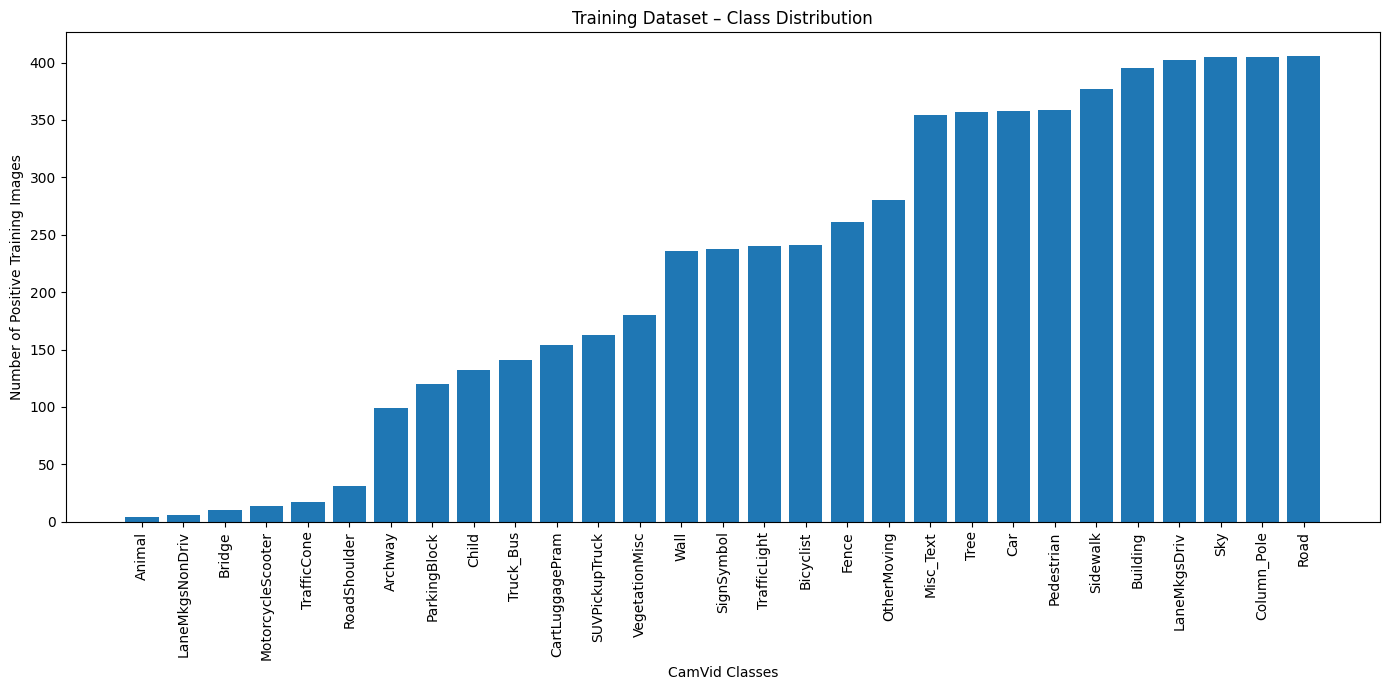

In [9]:
# Visualize class distribution
plt.figure(figsize=(14, 7))

plt.bar(
    class_distribution["class_name"],
    class_distribution["positive_samples"]
)

plt.xticks(rotation=90)
plt.xlabel("CamVid Classes")
plt.ylabel("Number of Positive Training Images")
plt.title("Training Dataset – Class Distribution")

plt.tight_layout()
plt.show()

## 4. Define CNN architecture

In [10]:
# CNN Model
class BaselineCNN(nn.Module):

    def __init__(self, num_classes=29):
        super(BaselineCNN, self).__init__()

        # Convolutional feature extraction
        self.features = nn.Sequential(

            # Block 1: 3 -> 32
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Block 2: 32 -> 64
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Block 3: 64 -> 128
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Block 4: 128 -> 256
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2)
        )

        # Global average pooling
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Classification head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.global_pool(x)

        x = self.classifier(x)

        return x

## 5. Initialize and inspect the model

In [11]:
# Model initialization
model = BaselineCNN(
    num_classes=NUM_CLASSES
).to(DEVICE)

print(model)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm

In [12]:
# Verify model input and output dimensions
dummy_input = torch.randn(
    2, 3, 224, 224
).to(DEVICE)

model.eval()

with torch.no_grad():
    dummy_output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)

assert dummy_output.shape == (2, NUM_CLASSES)

print("\nModel dimension validation passed.")

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 29])

Model dimension validation passed.


In [13]:
# Calculate trainable parameters
total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

Total parameters: 426,013
Trainable parameters: 426,013


## 6. Configure loss function and optimizer

In [14]:
# Define training configuration
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4

NUM_EPOCHS = 30

PATIENCE = 5

# Standard multi-label classification loss
criterion = nn.BCEWithLogitsLoss()

# Adam optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Learning rate:", LEARNING_RATE)
print("Maximum epochs:", NUM_EPOCHS)
print("Early stopping patience:", PATIENCE)

Loss function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Learning rate: 0.001
Maximum epochs: 30
Early stopping patience: 5


## 7. Training and validation functions

In [15]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    total_samples = 0

    for batch in loader:
        images = batch["image"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        running_loss += loss.item() * batch_size
        total_samples += batch_size

    return running_loss / total_samples

In [16]:
def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = images.size(0)
            running_loss += loss.item() * batch_size
            total_samples += batch_size

    return running_loss / total_samples

## 8. Implement the training loop

In [17]:
# Checkpoint directory
MODEL_DIR = DATASET_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "baseline_cnn_best.pth"

In [18]:
history = []

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0

start_time = time.time()

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, DEVICE
    )

    val_loss = validate_one_epoch(
        model, val_loader, criterion, DEVICE
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "classes": ACTIVE_CLASSES,
            "augmentation_config": augmentation_config
        }, BEST_MODEL_PATH)

        status = "Best model saved"

    else:
        patience_counter += 1
        status = f"No improvement: {patience_counter}/{PATIENCE}"

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {epoch_time:.1f}s | {status}"
    )

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch+1}.")
        break

total_time = time.time() - start_time

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Total training time:", round(total_time, 2), "seconds")
print("Best model saved at:", BEST_MODEL_PATH)

Epoch [01/30] Train Loss: 0.5670 | Val Loss: 0.5588 | Time: 19.2s | Best model saved
Epoch [02/30] Train Loss: 0.4076 | Val Loss: 0.3847 | Time: 19.1s | Best model saved
Epoch [03/30] Train Loss: 0.3745 | Val Loss: 0.3821 | Time: 19.8s | Best model saved
Epoch [04/30] Train Loss: 0.3539 | Val Loss: 0.3921 | Time: 18.5s | No improvement: 1/5
Epoch [05/30] Train Loss: 0.3421 | Val Loss: 0.3885 | Time: 18.6s | No improvement: 2/5
Epoch [06/30] Train Loss: 0.3301 | Val Loss: 0.3845 | Time: 20.3s | No improvement: 3/5
Epoch [07/30] Train Loss: 0.3240 | Val Loss: 0.3483 | Time: 18.4s | Best model saved
Epoch [08/30] Train Loss: 0.3157 | Val Loss: 0.3856 | Time: 18.6s | No improvement: 1/5
Epoch [09/30] Train Loss: 0.3074 | Val Loss: 0.3705 | Time: 19.0s | No improvement: 2/5
Epoch [10/30] Train Loss: 0.3017 | Val Loss: 0.3741 | Time: 20.6s | No improvement: 3/5
Epoch [11/30] Train Loss: 0.2869 | Val Loss: 0.4045 | Time: 19.0s | No improvement: 4/5
Epoch [12/30] Train Loss: 0.2868 | Val Loss:

## 9. Visualize training performance

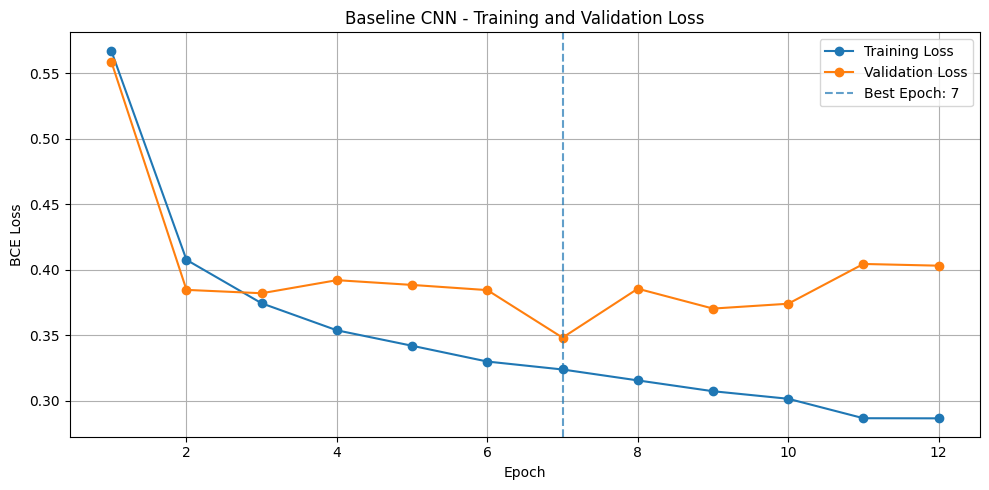

In [19]:
history_df = pd.DataFrame(history)

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    alpha=0.7,
    label=f"Best Epoch: {best_epoch}"
)

plt.title("Baseline CNN - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 10. Load the best model

In [21]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint loaded successfully.")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

Best checkpoint loaded successfully.
Best epoch: 7
Best validation loss: 0.34828988048765397


## 11. Generate test predictions and calculate test loss

In [24]:
def evaluate_on_test(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    total_samples = 0

    all_labels = []
    all_probabilities = []
    all_filenames = []

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = images.size(0)
            running_loss += loss.item() * batch_size
            total_samples += batch_size

            probabilities = torch.sigmoid(outputs)

            all_labels.append(labels.cpu().numpy())
            all_probabilities.append(probabilities.cpu().numpy())
            all_filenames.extend(batch["filename"])

    test_loss = running_loss / total_samples

    y_true = np.vstack(all_labels)
    y_prob = np.vstack(all_probabilities)

    return test_loss, y_true, y_prob, all_filenames


In [25]:
test_loss, y_true, y_prob, test_filenames = evaluate_on_test(
    model,
    test_loader,
    criterion,
    DEVICE
)
print("Test evaluation completed.")
print("Test Loss:", round(test_loss, 4))
print("Actual labels shape:", y_true.shape)
print("Predicted probabilities shape:", y_prob.shape)
print("Number of filenames:", len(test_filenames))

Test evaluation completed.
Test Loss: 0.3406
Actual labels shape: (124, 29)
Predicted probabilities shape: (124, 29)
Number of filenames: 124


## 12. Generate binary predictions

In [26]:
# Convert predicted probabilities into binary labels using the threshold of 0.5.

THRESHOLD = 0.5

y_pred = (y_prob >= THRESHOLD).astype(int)

print("Predictions generated successfully.")
print("Threshold:", THRESHOLD)
print("Total actual positive labels:", int(y_true.sum()))
print("Total predicted positive labels:", int(y_pred.sum()))

print("\nSample prediction:")
sample_index = 0

print("Filename:", test_filenames[sample_index])
print("Actual labels:", y_true[sample_index].astype(int))
print("Predicted labels:", y_pred[sample_index])

Predictions generated successfully.
Threshold: 0.5
Total actual positive labels: 1937
Total predicted positive labels: 1970

Sample prediction:
Filename: 0001TP_006690
Actual labels: [1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0]
Predicted labels: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


## 13. Calculate overall metrics

In [27]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

micro_precision = precision_score(
    y_true, y_pred, average="micro", zero_division=0
)

micro_recall = recall_score(
    y_true, y_pred, average="micro", zero_division=0
)

micro_f1 = f1_score(
    y_true, y_pred, average="micro", zero_division=0
)

macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

exact_match_accuracy = accuracy_score(y_true, y_pred)

overall_metrics = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Micro Precision",
        "Micro Recall",
        "Micro F1",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Exact-match Accuracy"
    ],
    "Value": [
        test_loss,
        micro_precision,
        micro_recall,
        micro_f1,
        macro_precision,
        macro_recall,
        macro_f1,
        exact_match_accuracy
    ]
})

display(overall_metrics.round(4))

,Metric,Value
0,Test Loss,0.3406
1,Micro Precision,0.8234
2,Micro Recall,0.8374
3,Micro F1,0.8303
4,Macro Precision,0.4523
5,Macro Recall,0.5458
6,Macro F1,0.4835
7,Exact-match Accuracy,0.0000


## 14. Per class evaluation

In [28]:
from sklearn.metrics import average_precision_score

per_class_results = []

for i, class_name in enumerate(ACTIVE_CLASSES):

    actual = y_true[:, i].astype(int)
    predicted = y_pred[:, i]
    probabilities = y_prob[:, i]

    positive_support = int(actual.sum())
    negative_support = len(actual) - positive_support

    precision = precision_score(
        actual, predicted, zero_division=0
    )

    recall = recall_score(
        actual, predicted, zero_division=0
    )

    f1 = f1_score(
        actual, predicted, zero_division=0
    )

    # AP is not informative when either class is absent.
    if positive_support > 0 and negative_support > 0:
        average_precision = average_precision_score(
            actual, probabilities
        )
    else:
        average_precision = np.nan

    per_class_results.append({
        "Class": class_name,
        "Positive Support": positive_support,
        "Negative Support": negative_support,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Average Precision": average_precision
    })

per_class_df = pd.DataFrame(per_class_results)

display(
    per_class_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

,Class,Positive Support,Negative Support,Precision,Recall,F1 Score,Average Precision
0,Road,124,0,1.0000,1.0000,1.0000,NaN
4,Building,124,0,1.0000,1.0000,1.0000,NaN
8,Tree,124,0,1.0000,1.0000,1.0000,NaN
6,Car,124,0,1.0000,1.0000,1.0000,NaN
5,Sidewalk,124,0,1.0000,1.0000,1.0000,NaN
3,LaneMkgsDriv,123,1,0.9919,1.0000,0.9960,0.9969
2,Column_Pole,123,1,0.9919,1.0000,0.9960,0.9982
1,Sky,123,1,0.9919,1.0000,0.9960,0.9969
7,Pedestrian,119,5,0.9597,1.0000,0.9794,0.9569
10,TrafficLight,107,17,0.8629,1.0000,0.9264,0.9552


## 15. Visualize per class evaluation

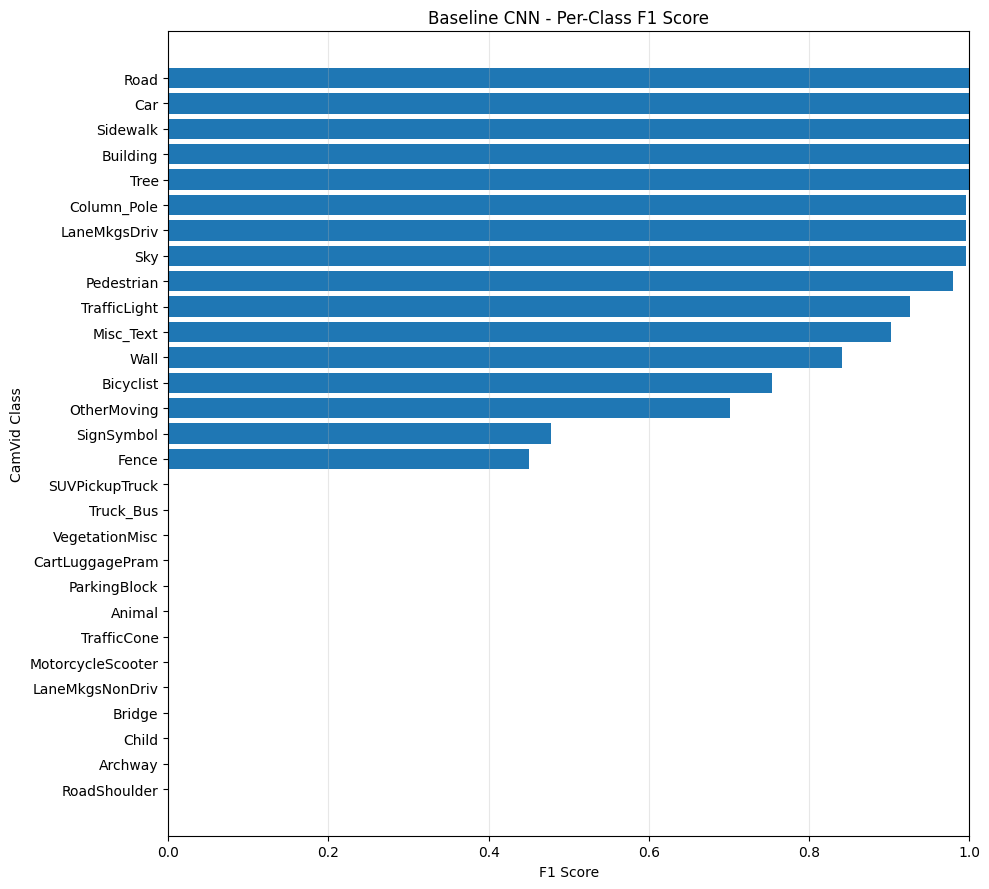

In [29]:
plot_df = per_class_df.sort_values(
    by="F1 Score",
    ascending=True
)

plt.figure(figsize=(10, 9))

plt.barh(
    plot_df["Class"],
    plot_df["F1 Score"]
)

plt.title("Baseline CNN - Per-Class F1 Score")
plt.xlabel("F1 Score")
plt.ylabel("CamVid Class")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Save evaluation result

In [31]:
EVALUATION_DIR = DATASET_DIR / "outputs"
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

overall_metrics.to_csv(
    EVALUATION_DIR / "baseline_cnn_overall_metrics.csv",
    index=False
)

per_class_df.to_csv(
    EVALUATION_DIR / "baseline_cnn_per_class_metrics.csv",
    index=False
)

print("Evaluation results saved:")
print(EVALUATION_DIR / "baseline_cnn_overall_metrics.csv")
print(EVALUATION_DIR / "baseline_cnn_per_class_metrics.csv")

Evaluation results saved:
/content/drive/MyDrive/AAI-521/project/datasets/camvid/outputs/baseline_cnn_overall_metrics.csv
/content/drive/MyDrive/AAI-521/project/datasets/camvid/outputs/baseline_cnn_per_class_metrics.csv


## 17. Class distribution across train, validation and test dataset

In [32]:
split_data = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

split_distribution = []

for class_name in ACTIVE_CLASSES:

    row = {"Class": class_name}

    for split_name, split_df in split_data.items():

        positive_count = int(split_df[class_name].sum())
        total_count = len(split_df)

        row[f"{split_name} Positive"] = positive_count
        row[f"{split_name} Negative"] = total_count - positive_count
        row[f"{split_name} Positive %"] = round(
            positive_count / total_count * 100, 2
        )

    split_distribution.append(row)

split_distribution_df = pd.DataFrame(split_distribution)

display(split_distribution_df)

,Class,Train Positive,Train Negative,Train Positive %,Validation Positive,Validation Negative,Validation Positive %,Test Positive,Test Negative,Test Positive %
0,Road,406,0,100.00,171,0,100.00,124,0,100.00
1,Sky,405,1,99.75,171,0,100.00,123,1,99.19
2,Column_Pole,405,1,99.75,171,0,100.00,123,1,99.19
3,LaneMkgsDriv,402,4,99.01,171,0,100.00,123,1,99.19
4,Building,395,11,97.29,168,3,98.25,124,0,100.00
5,Sidewalk,377,29,92.86,171,0,100.00,124,0,100.00
6,Car,358,48,88.18,161,10,94.15,124,0,100.00
7,Pedestrian,359,47,88.42,162,9,94.74,119,5,95.97
8,Tree,357,49,87.93,156,15,91.23,124,0,100.00
9,Misc_Text,354,52,87.19,143,28,83.63,102,22,82.26


## 18. Visualize positive class distribution

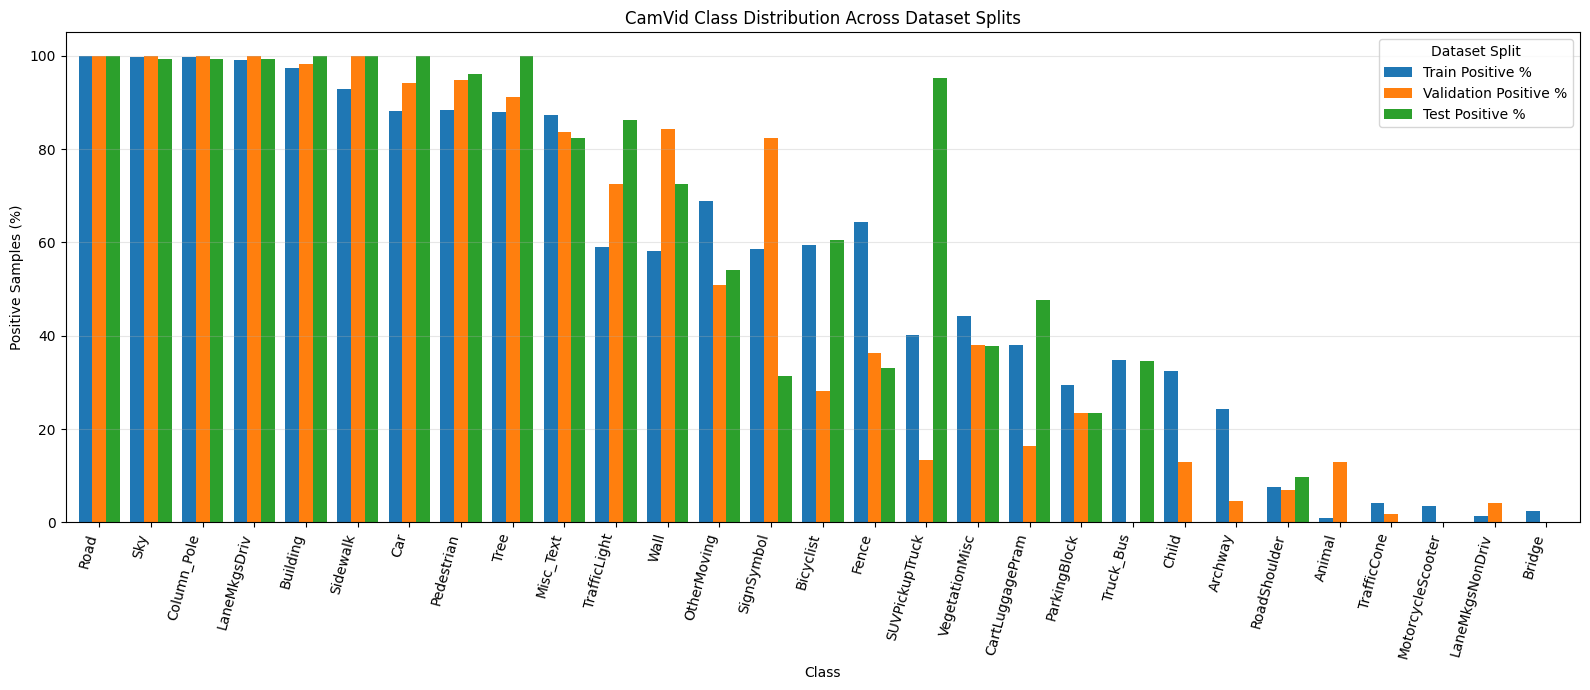

In [33]:
plot_df = split_distribution_df.set_index("Class")[
    ["Train Positive %", "Validation Positive %", "Test Positive %"]
]

plot_df.plot(
    kind="bar",
    figsize=(16, 7),
    width=0.8
)

plt.title("CamVid Class Distribution Across Dataset Splits")
plt.xlabel("Class")
plt.ylabel("Positive Samples (%)")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Dataset Split")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 19. Investigate predicted positive counts

In [34]:
prediction_distribution = []

for i, class_name in enumerate(ACTIVE_CLASSES):

    actual_positive = int(y_true[:, i].sum())
    predicted_positive = int(y_pred[:, i].sum())

    prediction_distribution.append({
        "Class": class_name,
        "Actual Positive": actual_positive,
        "Predicted Positive": predicted_positive,
        "Difference": predicted_positive - actual_positive
    })

prediction_distribution_df = pd.DataFrame(
    prediction_distribution
)

display(
    prediction_distribution_df.sort_values(
        by="Difference",
        ascending=False
    )
)

,Class,Actual Positive,Predicted Positive,Difference
13,SignSymbol,39,124,85
15,Fence,41,110,69
12,OtherMoving,67,124,57
14,Bicyclist,75,124,49
11,Wall,90,124,34
9,Misc_Text,102,124,22
10,TrafficLight,107,124,17
7,Pedestrian,119,124,5
1,Sky,123,124,1
2,Column_Pole,123,124,1


## 20. Examine prediction probability distribution

In [46]:

probability_summary = []

for i, class_name in enumerate(ACTIVE_CLASSES):

    probabilities = y_prob[:, i]

    probability_summary.append({
        "Class": class_name,
        "Min Probability": probabilities.min(),
        "Max Probability": probabilities.max(),
        "Mean Probability": probabilities.mean(),
        "Median Probability": np.median(probabilities),
        "Predictions >= 0.5": int((probabilities >= 0.5).sum())
    })

probability_summary_df = pd.DataFrame(probability_summary)

display(
    probability_summary_df.round(4)
)

,Class,Min Probability,Max Probability,Mean Probability,Median Probability,Predictions >= 0.5
0,Road,0.9729,0.9923,0.9864,0.9870,124
1,Sky,0.9727,0.9925,0.9866,0.9872,124
2,Column_Pole,0.9825,0.9947,0.9916,0.9921,124
3,LaneMkgsDriv,0.9767,0.9937,0.9891,0.9897,124
4,Building,0.9644,0.9881,0.9814,0.9824,124
5,Sidewalk,0.9450,0.9884,0.9753,0.9775,124
6,Car,0.8833,0.9400,0.9158,0.9192,124
7,Pedestrian,0.9076,0.9687,0.9468,0.9489,124
8,Tree,0.7375,0.8565,0.8135,0.8173,124
9,Misc_Text,0.8321,0.8945,0.8782,0.8811,124


In [47]:
# Class distribution by sequence
sequence_class_distribution = (
    train_df.groupby("sequence_id")[ACTIVE_CLASSES]
    .sum()
    .reset_index()
)

display(sequence_class_distribution)

,sequence_id,Road,Sky,Column_Pole,LaneMkgsDriv,Building,Sidewalk,Car,Pedestrian,Tree,...,ParkingBlock,Truck_Bus,Child,Archway,RoadShoulder,Animal,TrafficCone,MotorcycleScooter,LaneMkgsNonDriv,Bridge
0,0006R0,101,101,101,97,90,72,93,68,97,...,31,0,0,15,0,1,16,14,0,8
1,0016E5,305,304,304,305,305,305,265,291,260,...,89,141,132,84,31,3,1,0,6,2


In [48]:
# Combine all dataset splits
all_metadata = pd.concat([
    train_df.assign(dataset_split="train"),
    val_df.assign(dataset_split="validation"),
    test_df.assign(dataset_split="test")
], ignore_index=True)

print("Total images:", len(all_metadata))
print("Unique sequences:", all_metadata["sequence_id"].nunique())

print("\nImages per split:")
print(all_metadata["dataset_split"].value_counts())

print("\nUnique sequences per split:")
print(
    all_metadata.groupby("dataset_split")["sequence_id"]
    .nunique()
)

Total images: 701
Unique sequences: 4

Images per split:
dataset_split
train         406
validation    171
test          124
Name: count, dtype: int64

Unique sequences per split:
dataset_split
test          1
train         2
validation    1
Name: sequence_id, dtype: int64


In [49]:
# Identify which sequences belong to each split
sequence_split_mapping = (
    all_metadata.groupby(["sequence_id", "dataset_split"])
    .size()
    .reset_index(name="image_count")
    .sort_values(["sequence_id", "dataset_split"])
)

display(sequence_split_mapping)

,sequence_id,dataset_split,image_count
0,0001TP,test,124
1,0006R0,train,101
2,0016E5,train,305
3,Seq05VD,validation,171


In [50]:
# Validate sequence separation
sequence_split_counts = (
    all_metadata.groupby("sequence_id")["dataset_split"]
    .nunique()
)

overlapping_sequences = sequence_split_counts[
    sequence_split_counts > 1
]

print("Total unique sequences:", len(sequence_split_counts))
print("Sequences appearing in multiple splits:",
      len(overlapping_sequences))

if len(overlapping_sequences) > 0:
    print("\nPotential temporal leakage:")
    print(overlapping_sequences)
else:
    print("\nNo sequence overlap detected across splits.")

Total unique sequences: 4
Sequences appearing in multiple splits: 0

No sequence overlap detected across splits.


In [51]:
# Class presence across all sequences
sequence_class_distribution = (
    all_metadata.groupby(["sequence_id", "dataset_split"])[ACTIVE_CLASSES]
    .sum()
    .reset_index()
)

display(sequence_class_distribution)

,sequence_id,dataset_split,Road,Sky,Column_Pole,LaneMkgsDriv,Building,Sidewalk,Car,Pedestrian,...,ParkingBlock,Truck_Bus,Child,Archway,RoadShoulder,Animal,TrafficCone,MotorcycleScooter,LaneMkgsNonDriv,Bridge
0,0001TP,test,124,123,123,123,124,124,124,119,...,29,43,0,0,12,0,0,0,0,0
1,0006R0,train,101,101,101,97,90,72,93,68,...,31,0,0,15,0,1,16,14,0,8
2,0016E5,train,305,304,304,305,305,305,265,291,...,89,141,132,84,31,3,1,0,6,2
3,Seq05VD,validation,171,171,171,171,168,171,161,162,...,40,0,22,8,12,22,3,0,7,0


In [52]:
# Number of sequences containing each class
sequence_presence = []

for class_name in ACTIVE_CLASSES:

    sequence_count = (
        sequence_class_distribution
        .groupby("sequence_id")[class_name]
        .sum()
        .gt(0)
        .sum()
    )

    sequence_presence.append({
        "Class": class_name,
        "Sequences Containing Class": int(sequence_count),
        "Total Sequences": all_metadata["sequence_id"].nunique()
    })

sequence_presence_df = pd.DataFrame(sequence_presence)

display(
    sequence_presence_df.sort_values(
        "Sequences Containing Class"
    )
)

,Class,Sequences Containing Class,Total Sequences
26,MotorcycleScooter,1,4
20,Truck_Bus,2,4
21,Child,2,4
27,LaneMkgsNonDriv,2,4
28,Bridge,2,4
14,Bicyclist,3,4
25,TrafficCone,3,4
23,RoadShoulder,3,4
22,Archway,3,4
24,Animal,3,4


In [53]:
sequence_presence = []

for class_name in ACTIVE_CLASSES:

    sequence_count = (
        train_df.groupby("sequence_id")[class_name]
        .sum()
        .gt(0)
        .sum()
    )

    sequence_presence.append({
        "Class": class_name,
        "Sequences Containing Class": int(sequence_count),
        "Total Sequences": train_df["sequence_id"].nunique()
    })

sequence_presence_df = pd.DataFrame(sequence_presence)

display(
    sequence_presence_df.sort_values(
        by="Sequences Containing Class"
    )
)

,Class,Sequences Containing Class,Total Sequences
14,Bicyclist,1,2
20,Truck_Bus,1,2
23,RoadShoulder,1,2
26,MotorcycleScooter,1,2
27,LaneMkgsNonDriv,1,2
21,Child,1,2
2,Column_Pole,2,2
0,Road,2,2
7,Pedestrian,2,2
8,Tree,2,2


### Dataset Split and Evaluation Limitations

The CamVid dataset contains 701 images distributed across four independent sequences.

To prevent temporal data leakage, the dataset was divided at the sequence level:

- Training: 406 images from two sequences.
- Validation: 171 images from one sequence.
- Testing: 124 images from one sequence.

No sequence overlap was detected across the three splits.

Although this approach maintains sequence independence, the limited number of sequences introduces class-distribution imbalance. Some classes occur in only one or two sequences, resulting in limited or no positive examples in certain evaluation splits.

Consequently, per-class precision, recall, F1-score and Average Precision must be interpreted with consideration of their respective class support.

The current test results represent generalization to one unseen sequence and should not be interpreted as a comprehensive measure of performance across all possible driving environments.